In [1]:
import numpy as np 
import matplotlib.pyplot as plt
import scipy 


def simulation_wrapper(state0, params, update, sim_time, dt=0.1): 
    #euler method to see behaviour quickly
    
    states = np.zeros([int(sim_time/dt)+1, state0.shape[0], state0.shape[1]])
    states[0,:] = state0[:]
    
    
    for t in range(int(sim_time/dt)): 
        states[t+1] = update(params, states[t], dt)
        
    return states[1:]

rng = np.random.RandomState(seed = 5)

#set parameters between models
N = 2 #number of genes/mRNA with differeng length

#we sample the length here, so we can compare all models directly without having to average
l_mean = 1 #mean of length of the genes
l_sd = 1.
l_alpha = (l_mean/l_sd)**2 # parameters for gamma distribution
l_theta = l_sd**2/l_mean # parameters for gamma distribution
l = np.sort(rng.gamma(l_alpha,scale = l_theta,size = N)) #length of the mRNA chain

α_mean = 0.05
# α_sd = 0.2
α_rand = rng.randn(N)

β_mean = 5
β_sd = β_mean
β_alpha = (β_mean/β_sd)**2 # parameters for gamma distribution
β_theta = β_sd**2/β_mean # parameters for gamma distribution
β_rand = rng.randn(N) 

γ_mean = .3
γ_sd = 0.0001
γ_rand = rng.randn(N)

#stalling rate, not sure which distribution to follow
δ_mean = .3
δ_sd = 0.0001
δ_rand = rng.randn(N)

x0_mean = 1
x0_sd = 0.001
x0 = np.array([x0_mean,x0_mean]) #+ x0_sd*np.random.randn(N)


In [2]:
def synth_ribosomes_model(parameters, state_var, dt ):
    #parmeters are: 
    #alpha, beta, and gamma (initation, elongation, degradation) rate and R (numer of total ribosomes)
    
    #parameters is a dictionary with the different parameters 
    #we just read them out below to return the updated amounts of interactions
    
    xpre_vec = state_var[0] # small unit bound, large unit missing
    x_vec = state_var[1]   #free mRNA concentrations
    xr_vec = state_var[2]  # bound mRNA ribosome concentrations, translating
    xrstar_vec = state_var[3] #reinitiation target complex
    y_vec = state_var[4]   #protein concentrations
    y_free = parameters['Y_max'] - np.sum(y_vec)  #concentration of free proteins
    rs = parameters['Rs'] - np.sum(xpre_vec) - np.sum(xr_vec) - np.sum(xrstar_vec) #short free ribosomes
    rl = parameters['Rl'] - np.sum(xr_vec) - np.sum(xrstar_vec)  # free long ribosomes
    

    new_xpre_vec = xpre_vec + dt * (parameters['α_1']  * rs * x_vec  - parameters['α_2'] * rl * xpre_vec)
    new_x_vec = x_vec + dt * (-parameters['α_1']  * rs * x_vec  + parameters['β'] * xr_vec* y_free)
    new_xr_vec = xr_vec + dt * (parameters['α_2'] * rl * xpre_vec + parameters['α_3'] * xrstar_vec - parameters['β'] * xr_vec* y_free - parameters['β'] * xr_vec* y_free)
    new_xrstar_vec = xrstar_vec + dt * (- parameters['α_3'] * xrstar_vec + parameters['β'] * xr_vec* y_free)
    new_y_vec = y_vec + dt * ( parameters['β'] * xr_vec * y_free + parameters['β'] * xr_vec* y_free - parameters['δ'] * y_vec)

    #fix returns and run
    return new_xpre_vec, new_x_vec, new_xr_vec, new_xrstar_vec, new_y_vec


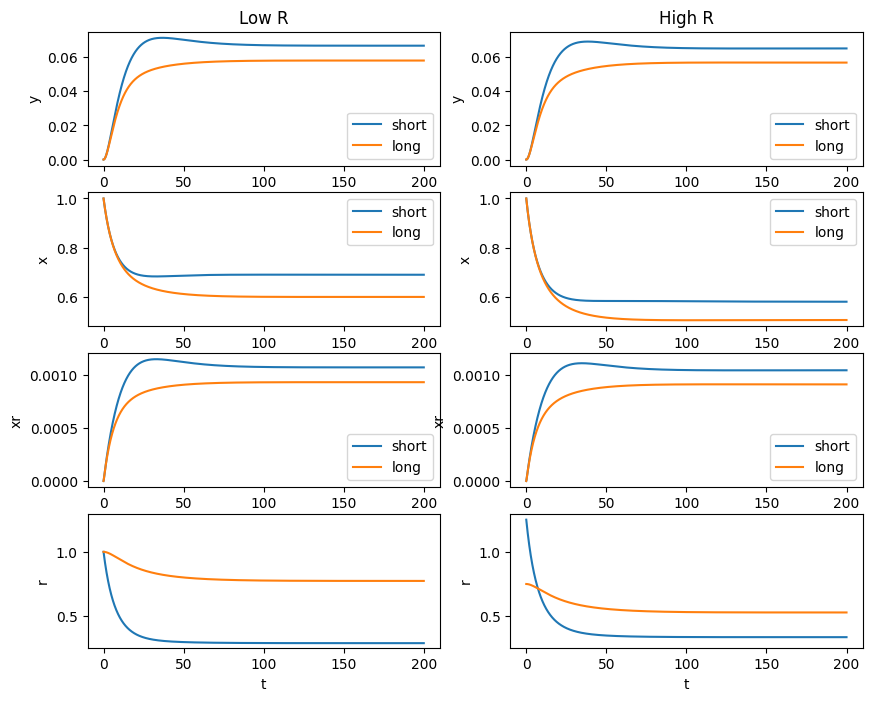

Ratio (short/long) in low condition:1.1500723330550562
Ratio (short/long) in high condition:1.1461353678995558


In [3]:
#we just set the rates and not sample yet, to see how this system with a "postive" trap behaves

α_1 =  α_mean  #small ribosome attaching
α_2 = α_mean #big ribosome attaching
α_3 = np.array([α_mean*4,α_mean]) #reinitiation, now this is true, because shorter mRNA are circular easier
β =  β_mean #simple length dependence
δ = δ_mean


#we sample the rates from gamma distributions as this is the most reasonable to assume for biological rates

#####no length dependency 


# calculate parameters  
#α = α_mean + 0.001* α_rand
#β = β_mean + 0.001* β_rand
#γ = γ_mean + γ_sd* γ_rand
#δ = δ_mean + δ_sd * δ_rand



parameters = dict()
parameters['α_1'] = α_1
parameters['α_2'] = α_2
parameters['α_3'] = α_3
parameters['β'] = β
#parameters['γ'] = γ
parameters['δ'] = δ
#parameters['l'] = l
b_R = 1
parameters['Rs'] = b_R #this can be set to be imbalanced
parameters['Rl'] = b_R
parameters['Y_max'] = N

#init_state =np.array([x0, np.zeros([N]), (Y_max/N)*np.ones([N]), parameters['Y_max']*np.ones([N])])#[x0; zeros(N); (Y_max/N)*ones(N); zeros(N)]
#free mRNA is actually now the 2nd, the first is mRNA which has a short ribosome subunit attached
init_state =np.array([np.zeros([N]),x0,np.zeros([N]), np.zeros([N]), np.zeros([N])]) 
sim_time = 200
dt = 0.001

baseline_low = simulation_wrapper(init_state,parameters, synth_ribosomes_model, sim_time, dt) 

parameters['Rs'] = 1.25 #this can be set to be imbalanced
parameters['Rl'] = 0.75 #overproduction of short, kinda pushing it away, but might be first indication
#parameters['R'] = 5
baseline_high = simulation_wrapper(init_state,parameters, synth_ribosomes_model, sim_time, dt) 

fig, ax = plt.subplots(4,2,figsize = (10,8))
ax[0,0].plot(np.arange(0,sim_time,dt), baseline_low[:,4,0], label = 'short')
ax[0,0].plot(np.arange(0,sim_time,dt), baseline_low[:,4,1], label = 'long')
ax[0,0].set_ylabel('y')
ax[0,0].set_xlabel('t')
ax[0,0].legend()
ax[0,1].plot(np.arange(0,sim_time,dt), baseline_high[:,4,0], label = 'short')
ax[0,1].plot(np.arange(0,sim_time,dt), baseline_high[:,4,1], label = 'long')
ax[0,1].set_ylabel('y')
ax[0,1].set_xlabel('t')
ax[0,1].legend()
ymin, ymax = ax[0,0].get_ylim()
ymin1, ymax1 = ax[0,1].get_ylim()
ax[0,1].set_ylim(min(ymin,ymin1), max(ymax,ymax1))
ax[0,0].set_ylim(min(ymin,ymin1), max(ymax,ymax1))

ax[1,0].plot(np.arange(0,sim_time,dt), baseline_low[:,1,0], label = 'short')
ax[1,0].plot(np.arange(0,sim_time,dt), baseline_low[:,1,1], label = 'long')
ax[1,0].set_ylabel('x')
ax[1,0].set_xlabel('t')
ax[1,0].legend()
ax[1,1].plot(np.arange(0,sim_time,dt), baseline_high[:,1,0], label = 'short')
ax[1,1].plot(np.arange(0,sim_time,dt), baseline_high[:,1,1], label = 'long')
ax[1,1].set_ylabel('x')
ax[1,1].set_xlabel('t')
ax[1,1].legend()
ymin, ymax = ax[1,0].get_ylim()
ymin1, ymax1 = ax[1,1].get_ylim()
ax[1,1].set_ylim(min(ymin,ymin1), max(ymax,ymax1))
ax[1,0].set_ylim(min(ymin,ymin1), max(ymax,ymax1))

ax[2,0].plot(np.arange(0,sim_time,dt), baseline_low[:,2,0], label = 'short')
ax[2,0].plot(np.arange(0,sim_time,dt), baseline_low[:,2,1], label = 'long')
ax[2,0].set_ylabel('xr')
ax[2,0].set_xlabel('t')
ax[2,0].legend()
ax[2,1].plot(np.arange(0,sim_time,dt), baseline_high[:,2,0], label = 'short')
ax[2,1].plot(np.arange(0,sim_time,dt), baseline_high[:,2,1], label = 'long')
ax[2,1].set_ylabel('xr')
ax[2,1].set_xlabel('t')
ax[2,1].legend()
ymin, ymax = ax[2,0].get_ylim()
ymin1, ymax1 = ax[2,1].get_ylim()
ax[2,1].set_ylim(min(ymin,ymin1), max(ymax,ymax1))
ax[2,0].set_ylim(min(ymin,ymin1), max(ymax,ymax1))

ax[3,0].plot(np.arange(0,sim_time,dt), b_R-np.sum(baseline_low[:,0,:], axis = 1)-np.sum(baseline_low[:,2,:], axis = 1)-np.sum(baseline_low[:,3,:], axis = 1))
ax[3,0].plot(np.arange(0,sim_time,dt), b_R-np.sum(baseline_low[:,2,:], axis = 1)-np.sum(baseline_low[:,3,:], axis = 1))
ax[3,0].set_ylabel('r')
ax[3,0].set_xlabel('t')
ax[3,1].plot(np.arange(0,sim_time,dt), parameters['Rs']-np.sum(baseline_high[:,0,:], axis = 1)-np.sum(baseline_high[:,2,:], axis = 1)-np.sum(baseline_high[:,3,:], axis = 1))
ax[3,1].plot(np.arange(0,sim_time,dt), parameters['Rl']-np.sum(baseline_high[:,2,:], axis = 1)-np.sum(baseline_high[:,3,:], axis = 1))
ax[3,1].set_ylabel('r')
ax[3,1].set_xlabel('t')
ax[0,0].set_title('Low R')
ax[0,1].set_title('High R')
ymin, ymax = ax[3,0].get_ylim()
ymin1, ymax1 = ax[3,1].get_ylim()
ax[3,1].set_ylim(min(ymin,ymin1), max(ymax,ymax1))
ax[3,0].set_ylim(min(ymin,ymin1), max(ymax,ymax1))
plt.show()

print('Ratio (short/long) in low condition:'+str(baseline_low[-1,4,0]/baseline_low[-1,4,1]) )
print('Ratio (short/long) in high condition:'+str(baseline_high[-1,4,0]/baseline_high[-1,4,1]) )



########length dependency




# # calculate parameters  
# α = α_rand * 0 + 0.001 * np.mean(α_rand) + α_mean #α_mean / l + 0.001* α_rand
# β = β_mean / l + 0.001* β_rand
# γ = γ_mean  + γ_sd* γ_rand
# δ = δ_mean + δ_sd * δ_rand


# parameters = dict()
# parameters['α'] = α
# parameters['β'] = β
# parameters['γ'] = γ
# parameters['δ'] = δ
# parameters['l'] = l
# parameters['R'] = 1
# parameters['Y_max'] = N

# #init_state =np.array([x0, np.zeros([N]), (Y_max/N)*np.ones([N]), parameters['Y_max']*np.ones([N])])#[x0; zeros(N); (Y_max/N)*ones(N); zeros(N)]
# init_state =np.array([x0, np.zeros([N]),np.zeros([N]), np.zeros([N])]) 
# dt = 0.001

# baseline_low = simulation_wrapper(init_state,parameters, synth_ribosomes_model, sim_time, dt) 


# parameters['R'] = 5
# baseline_high = simulation_wrapper(init_state,parameters, synth_ribosomes_model, sim_time, dt) 

# fig, ax = plt.subplots(4,2,figsize = (10,8))
# ax[0,0].plot(np.arange(0,sim_time,dt), baseline_low[:,2,0], label = 'short')
# ax[0,0].plot(np.arange(0,sim_time,dt), baseline_low[:,2,1], label = 'long')
# ax[0,0].set_ylabel('y')
# ax[0,0].set_xlabel('t')
# ax[0,0].legend()
# ax[1,0].plot(np.arange(0,sim_time,dt), baseline_low[:,0,0], label = 'short')
# ax[1,0].plot(np.arange(0,sim_time,dt), baseline_low[:,0,1], label = 'long')
# ax[1,0].set_ylabel('x')
# ax[1,0].set_xlabel('t')
# ax[1,0].legend()
# ax[2,0].plot(np.arange(0,sim_time,dt), baseline_low[:,1,0], label = 'short')
# ax[2,0].plot(np.arange(0,sim_time,dt), baseline_low[:,1,1], label = 'long')
# ax[2,0].set_ylabel('xr')
# ax[2,0].set_xlabel('t')
# ax[2,0].legend()
# ax[3,0].plot(np.arange(0,sim_time,dt), parameters['R']-np.sum(baseline_low[:,1,:], axis = 1))
# ax[3,0].set_ylabel('r')
# ax[3,0].set_xlabel('t')

# ax[0,1].plot(np.arange(0,sim_time,dt), baseline_high[:,2,0], label = 'short')
# ax[0,1].plot(np.arange(0,sim_time,dt), baseline_high[:,2,1], label = 'long')
# ax[0,1].set_ylabel('y')
# ax[0,1].set_xlabel('t')
# ax[0,1].legend()
# ax[1,1].plot(np.arange(0,sim_time,dt), baseline_high[:,0,0], label = 'short')
# ax[1,1].plot(np.arange(0,sim_time,dt), baseline_high[:,0,1], label = 'long')
# ax[1,1].set_ylabel('x')
# ax[1,1].set_xlabel('t')
# ax[1,1].legend()
# ax[2,1].plot(np.arange(0,sim_time,dt), baseline_high[:,1,0], label = 'short')
# ax[2,1].plot(np.arange(0,sim_time,dt), baseline_high[:,1,1], label = 'long')
# ax[2,1].set_ylabel('xr')
# ax[2,1].set_xlabel('t')
# ax[2,1].legend()
# ax[3,1].plot(np.arange(0,sim_time,dt), parameters['R']-np.sum(baseline_high[:,1,:], axis = 1))
# ax[3,1].set_ylabel('r')
# ax[3,1].set_xlabel('t')
# ax[0,0].set_title('Low R')
# ax[0,1].set_title('High R')
# plt.show()

# print('Ratio (short/long) in low condition:'+str(baseline_low[-1,2,0]/baseline_low[-1,2,1]) )
# print('Ratio (short/long) in high condition:'+str(baseline_high[-1,2,0]/baseline_high[-1,2,1]) )


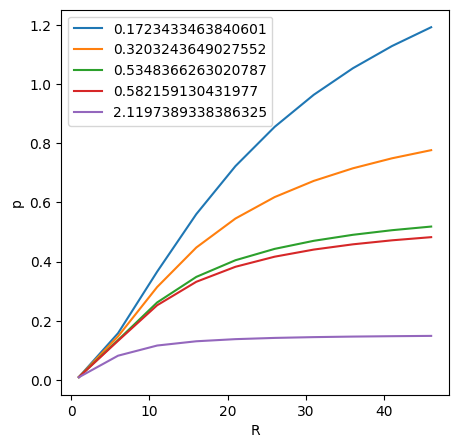

In [4]:
#mRNA is limiting: N < R



#look at the relationship of R and x dependent on the length
N = 5 #number of genes/mRNA with differeng length

#we sample the length here, so we can compare all models directly without having to average
l_mean = 1 #mean of length of the genes
l_sd = 1.
l_alpha = (l_mean/l_sd)**2 # parameters for gamma distribution
l_theta = l_sd**2/l_mean # parameters for gamma distribution
l = np.sort(rng.gamma(l_alpha,scale = l_theta,size = N)) #length of the mRNA chain

#parameters = dict()
α_3 = α_mean/l
parameters['α_3'] = α_3
parameters['Y_max'] = N

β = β_mean/l
parameters['β'] = β

x0_mean = 1
x0_sd = 0.001
x0 = x0_mean + x0_sd*rng.randn(N)



Rs = np.arange(1,50,5)
results = np.zeros([Rs.shape[0],N])

for r in range(Rs.shape[0]):

    parameters['Rs'] = Rs[r]*0.5
    parameters['Rl'] = Rs[r]*0.5

    #init_state =np.array([x0, np.zeros([N]), (Y_max/N)*np.ones([N]), parameters['Y_max']*np.ones([N])])#[x0; zeros(N); (Y_max/N)*ones(N); zeros(N)]
    init_state =np.array([np.zeros([N]),x0,np.zeros([N]), np.zeros([N]), np.zeros([N])]) 

    baseline = simulation_wrapper(init_state,parameters,synth_ribosomes_model, sim_time*2, dt) 
    results[r]= baseline[-1,4,:]
    

fig, ax = plt.subplots(1,1,figsize = (5, 5))
for i in range(N):
    ax.plot(Rs, results[:,i], label = l[i])
ax.set_xlabel('R')
ax.set_ylabel('p')
ax.legend()
plt.show()

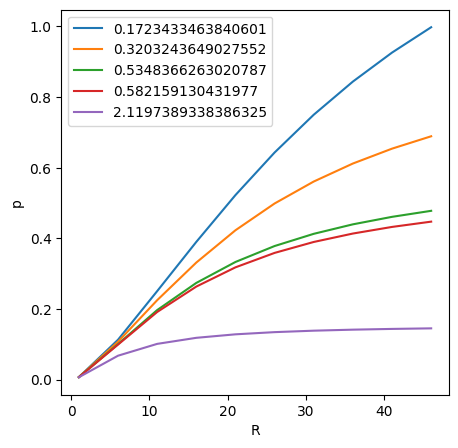

In [5]:
#mRNA is limiting: N < R

for r in range(Rs.shape[0]):

    parameters['Rs'] = Rs[r]*0.75
    parameters['Rl'] = Rs[r]*0.25

    #init_state =np.array([x0, np.zeros([N]), (Y_max/N)*np.ones([N]), parameters['Y_max']*np.ones([N])])#[x0; zeros(N); (Y_max/N)*ones(N); zeros(N)]
    init_state =np.array([np.zeros([N]),x0,np.zeros([N]), np.zeros([N]), np.zeros([N])]) 

    baseline = simulation_wrapper(init_state,parameters,synth_ribosomes_model, sim_time*2, dt) 
    results[r]= baseline[-1,4,:]
    

fig, ax = plt.subplots(1,1,figsize = (5, 5))
for i in range(N):
    ax.plot(Rs, results[:,i], label = l[i])
ax.set_xlabel('R')
ax.set_ylabel('p')
ax.legend()
plt.show()

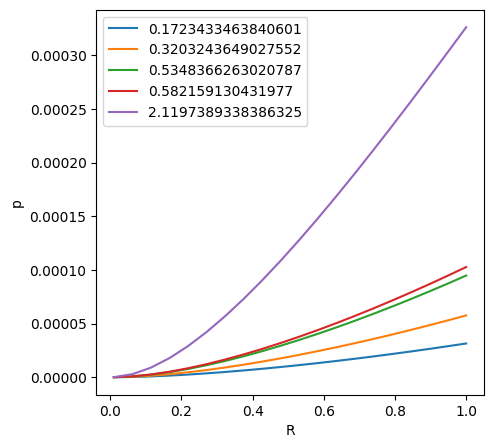

In [6]:
#ribosomes is limiting: N > R

Rs = np.linspace(0.01,1,20)
results = np.zeros([Rs.shape[0],N])

for r in range(Rs.shape[0]):

    parameters['Rs'] = Rs[r]
    parameters['Rl'] = Rs[r]

    #init_state =np.array([x0, np.zeros([N]), (Y_max/N)*np.ones([N]), parameters['Y_max']*np.ones([N])])#[x0; zeros(N); (Y_max/N)*ones(N); zeros(N)]
    init_state =np.array([np.zeros([N]),x0,np.zeros([N]), np.zeros([N]), np.zeros([N])])  

    baseline = simulation_wrapper(init_state,parameters,synth_ribosomes_model, sim_time, dt) 
    results[r]= baseline[-1,2,:]
    

fig, ax = plt.subplots(1,1,figsize = (5,5))
for i in range(N):
    ax.plot(Rs, results[:,i], label = l[i])
ax.set_xlabel('R')
ax.set_ylabel('p')
ax.legend()
plt.show()